# Image-Cultivar Mapping Validation

**Purpose:** Validate that every training image can be reliably associated with exactly one cultivar label using `train_cultivar_mapping.csv`. Produce a clean, reproducible mapping ready for balanced subset creation.

## 1. Imports

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

## 2. Configuration

Set `DATASET_ROOT` to the directory that contains the PNG images and CSV files.
The dataset is flat: images and CSVs live directly inside `DATASET_ROOT`.

In [2]:
DATASET_ROOT  = Path("../../Dataset")
MAPPING_FILE  = DATASET_ROOT / "train_cultivar_mapping.csv"
GERMPLASM_FILE = DATASET_ROOT / "germplasm.csv"
RESULTS_DIR   = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

IMG_COL      = "image"
CULTIVAR_COL = "cultivar"

## 3. Path Verification

In [3]:
assert DATASET_ROOT.exists(),  f"DATASET_ROOT not found: {DATASET_ROOT.resolve()}"
assert MAPPING_FILE.exists(),  f"Mapping CSV not found: {MAPPING_FILE.resolve()}"
assert GERMPLASM_FILE.exists(), f"Germplasm CSV not found: {GERMPLASM_FILE.resolve()}"
print("All paths verified.")
print(f"  DATASET_ROOT : {DATASET_ROOT.resolve()}")
print(f"  MAPPING_FILE : {MAPPING_FILE.resolve()}")
print(f"  GERMPLASM_FILE: {GERMPLASM_FILE.resolve()}")

All paths verified.
  DATASET_ROOT : C:\Users\nihar\OneDrive\Desktop\Water To Pixels\Dataset
  MAPPING_FILE : C:\Users\nihar\OneDrive\Desktop\Water To Pixels\Dataset\train_cultivar_mapping.csv
  GERMPLASM_FILE: C:\Users\nihar\OneDrive\Desktop\Water To Pixels\Dataset\germplasm.csv


## 4. Load and Inspect the Mapping CSV

In [4]:
raw = pd.read_csv(MAPPING_FILE)
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())
print("\nData types:")
print(raw.dtypes)
print("\nMissing values:")
print(raw.isnull().sum())

Shape: (22194, 2)
Columns: ['image', 'cultivar']

Data types:
image       object
cultivar    object
dtype: object

Missing values:
image       0
cultivar    1
dtype: int64


In [5]:
print("First 5 rows:")
raw.head()

First 5 rows:


,image,cultivar
0,2017-06-16__12-24-20-930.png,PI_257599
1,2017-06-02__16-48-57-866.png,PI_154987
2,2017-06-12__13-18-07-707.png,PI_92270
3,2017-06-22__13-18-06-841.png,PI_152651
4,2017-06-26__12-56-48-642.png,PI_176766


In [6]:
print("Last 5 rows:")
raw.tail()

Last 5 rows:


,image,cultivar
22189,2017-06-16__12-27-16-266.png,PI_170787
22190,2017-06-28__11-19-57-454.png,PI_156393
22191,2017-06-28__10-20-32-417.png,PI_152923
22192,2017-06-28__12-47-02-714.png,PI_257599
22193,2017-06-04__13-12-56-053.png,PI_196586


**Confirmed column names:**
- Image filename column: `image`
- Cultivar label column: `cultivar`

## 5. Normalize Filenames (for comparison only)

In [7]:
df = raw.copy()
# Strip accidental whitespace only - do NOT rename or modify actual files
df[IMG_COL]      = df[IMG_COL].astype(str).str.strip()
df[CULTIVAR_COL] = df[CULTIVAR_COL].astype(str).str.strip()
# Restore genuine NaN for missing cultivar
df.loc[raw[CULTIVAR_COL].isnull(), CULTIVAR_COL] = float("nan")
print("Normalization complete. Original CSV is unchanged.")

Normalization complete. Original CSV is unchanged.


## 6. Duplicate Mapping Entries

In [8]:
total_rows    = len(df)
unique_images = df[IMG_COL].nunique()
dup_mask      = df.duplicated(IMG_COL, keep=False)
dup_rows      = dup_mask.sum()

print(f"Total rows          : {total_rows}")
print(f"Unique image names  : {unique_images}")
print(f"Rows with duplicated image filename: {dup_rows}")

Total rows          : 22194
Unique image names  : 22194
Rows with duplicated image filename: 0


In [9]:
if dup_rows > 0:
    print("Duplicated entries:")
    print(df[dup_mask].sort_values(IMG_COL))
else:
    print("No duplicate image filenames found.")

No duplicate image filenames found.


## 7. Conflicting Labels Check

In [10]:
label_counts = df.groupby(IMG_COL)[CULTIVAR_COL].nunique()
conflicting  = label_counts[label_counts > 1]
single_label = label_counts[label_counts == 1]

print(f"Images with exactly one cultivar label : {len(single_label)}")
print(f"Images with conflicting cultivar labels: {len(conflicting)}")

if len(conflicting) > 0:
    print("\nConflicting label report:")
    for img in conflicting.index:
        rows = df[df[IMG_COL] == img]
        print(f"  {img}: {rows[CULTIVAR_COL].tolist()}")

Images with exactly one cultivar label : 22193
Images with conflicting cultivar labels: 0


## 8. Image File Existence Check

In [11]:
# Collect all PNG filenames physically present in DATASET_ROOT
physical_files = {p.name for p in DATASET_ROOT.glob("*.png")}
mapped_images  = set(df[IMG_COL].dropna().unique())

physically_present = mapped_images & physical_files
mapped_missing     = mapped_images - physical_files
unmapped_physical  = physical_files - mapped_images

print(f"Physical PNG files on disk          : {len(physical_files)}")
print(f"Unique images in mapping CSV        : {len(mapped_images)}")
print(f"Mapped images physically present    : {len(physically_present)}")
print(f"Mapped images missing from disk     : {len(mapped_missing)}")
print(f"Physical images not in mapping CSV  : {len(unmapped_physical)}")

if mapped_missing:
    print("\nMissing images (first 10):")
    for f in sorted(mapped_missing)[:10]:
        print(" ", f)

Physical PNG files on disk          : 5000
Unique images in mapping CSV        : 22194
Mapped images physically present    : 5000
Mapped images missing from disk     : 17194
Physical images not in mapping CSV  : 0

Missing images (first 10):
  .DS_Store
  2017-06-01__10-26-27-479.png
  2017-06-01__10-26-28-944.png
  2017-06-01__10-26-37-978.png
  2017-06-01__10-26-40-989.png
  2017-06-01__10-26-43-983.png
  2017-06-01__10-26-45-452.png
  2017-06-01__10-27-01-980.png
  2017-06-01__10-27-03-446.png
  2017-06-01__10-27-53-288.png


## 9. Mapping Status Categories

In [12]:
def assign_status(row, physical_files, conflicting_images):
    img = row[IMG_COL]
    cultivar = row[CULTIVAR_COL]
    if pd.isnull(cultivar) or str(cultivar).strip() == "":
        return "MISSING_CULTIVAR"
    if img in conflicting_images:
        return "CONFLICTING_LABEL"
    if img not in physical_files:
        return "MISSING_IMAGE"
    return "VALID"

conflicting_images = set(conflicting.index)
df["status"] = df.apply(assign_status, axis=1,
                         physical_files=physical_files,
                         conflicting_images=conflicting_images)

print("Status distribution:")
print(df["status"].value_counts())

Status distribution:
status
MISSING_IMAGE       17193
VALID                5000
MISSING_CULTIVAR        1
Name: count, dtype: int64


## 10. Create Clean Validated Mapping

In [13]:
# Keep only VALID rows
validated = df[df["status"] == "VALID"][[IMG_COL, CULTIVAR_COL]].copy()
# Drop exact duplicate rows (same image + same cultivar)
validated = validated.drop_duplicates()
validated = validated.reset_index(drop=True)

# Issue report: all excluded rows
issues = df[df["status"] != "VALID"].copy()

print(f"Validated mapping size : {len(validated)}")
print(f"Excluded / issue rows  : {len(issues)}")
print("\nIssue rows:")
print(issues[[IMG_COL, CULTIVAR_COL, "status"]])

Validated mapping size : 5000
Excluded / issue rows  : 17194

Issue rows:
                              image   cultivar            status
3246   2017-06-23__16-27-06-445.png  PI_154844     MISSING_IMAGE
3329                      .DS_Store        NaN  MISSING_CULTIVAR
3447   2017-06-13__11-35-44-977.png  PI_154844     MISSING_IMAGE
3514   2017-06-13__11-38-22-362.png  PI_154844     MISSING_IMAGE
3527   2017-06-14__13-38-32-490.png  PI_154844     MISSING_IMAGE
...                             ...        ...               ...
22189  2017-06-16__12-27-16-266.png  PI_170787     MISSING_IMAGE
22190  2017-06-28__11-19-57-454.png  PI_156393     MISSING_IMAGE
22191  2017-06-28__10-20-32-417.png  PI_152923     MISSING_IMAGE
22192  2017-06-28__12-47-02-714.png  PI_257599     MISSING_IMAGE
22193  2017-06-04__13-12-56-053.png  PI_196586     MISSING_IMAGE

[17194 rows x 3 columns]


In [14]:
out_path = RESULTS_DIR / "validated_image_cultivar_mapping.csv"
validated.to_csv(out_path, index=False)
print(f"Saved: {out_path}")

Saved: ..\results\validated_image_cultivar_mapping.csv


## 11. Validation Report

In [15]:
status_counts = df["status"].value_counts().to_dict()

report = pd.DataFrame([
    {"metric": "Total mapping rows",                "value": total_rows},
    {"metric": "Unique mapped images",              "value": unique_images},
    {"metric": "Duplicate image filenames",         "value": dup_rows},
    {"metric": "Images with conflicting labels",    "value": len(conflicting)},
    {"metric": "Missing cultivar labels",           "value": int(df[CULTIVAR_COL].isnull().sum())},
    {"metric": "Mapped images physically present",  "value": len(physically_present)},
    {"metric": "Mapped images physically missing",  "value": len(mapped_missing)},
    {"metric": "Unmapped physical images",          "value": len(unmapped_physical)},
    {"metric": "Valid image-cultivar pairs",        "value": len(validated)},
])

report_path = RESULTS_DIR / "mapping_validation_report.csv"
report.to_csv(report_path, index=False)
print(report.to_string(index=False))
print(f"\nSaved: {report_path}")

                          metric  value
              Total mapping rows  22194
            Unique mapped images  22194
       Duplicate image filenames      0
  Images with conflicting labels      0
         Missing cultivar labels      1
Mapped images physically present   5000
Mapped images physically missing  17194
        Unmapped physical images      0
      Valid image-cultivar pairs   5000

Saved: ..\results\mapping_validation_report.csv


## 12. Validated Cultivar Distribution

In [16]:
dist = validated[CULTIVAR_COL].value_counts().reset_index()
dist.columns = ["cultivar", "image_count"]
dist = dist.sort_values("cultivar").reset_index(drop=True)

n_cultivars = len(dist)
print(f"Unique cultivars     : {n_cultivars}")
print(f"Min images/cultivar  : {dist['image_count'].min()}")
print(f"Max images/cultivar  : {dist['image_count'].max()}")
print(f"Mean images/cultivar : {dist['image_count'].mean():.1f}")
print(f"Median images/cultivar: {dist['image_count'].median():.1f}")

dist_path = RESULTS_DIR / "validated_cultivar_distribution.csv"
dist.to_csv(dist_path, index=False)
print(f"\nSaved: {dist_path}")

Unique cultivars     : 100
Min images/cultivar  : 50
Max images/cultivar  : 50
Mean images/cultivar : 50.0
Median images/cultivar: 50.0

Saved: ..\results\validated_cultivar_distribution.csv


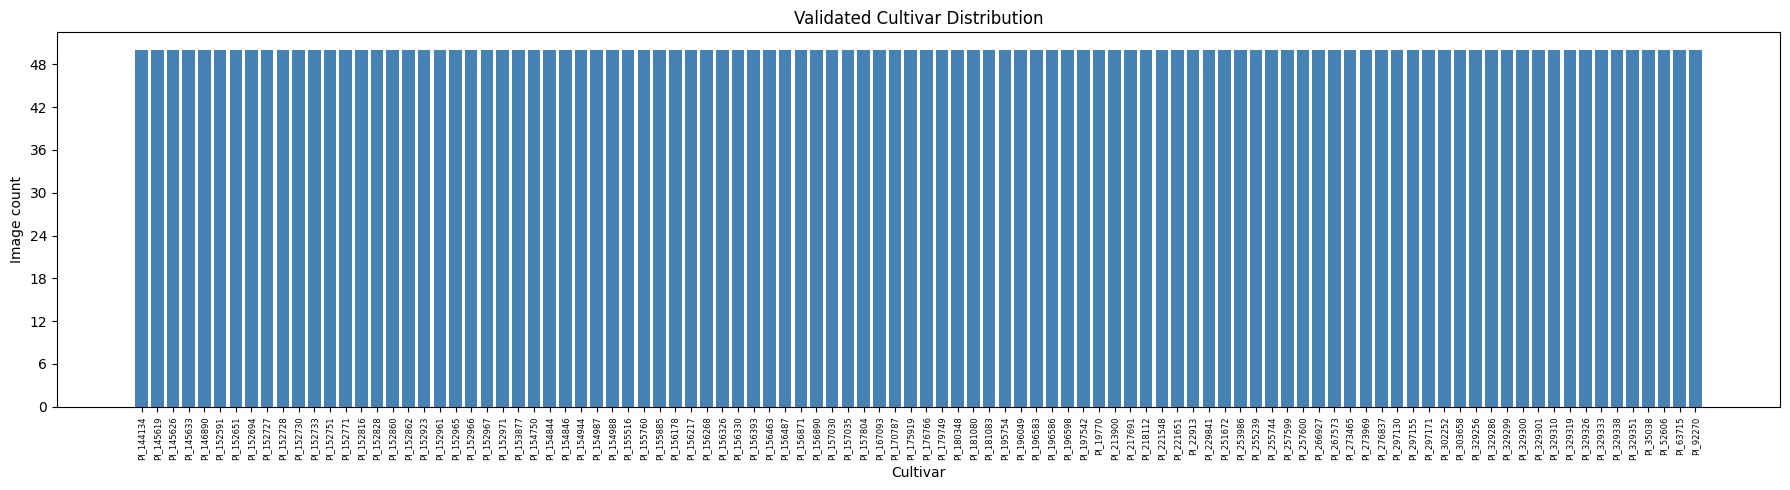

Saved: ..\results\validated_cultivar_distribution.png


In [17]:
fig, ax = plt.subplots(figsize=(18, 5))
ax.bar(dist["cultivar"], dist["image_count"], color="steelblue", width=0.8)
ax.set_xlabel("Cultivar", fontsize=10)
ax.set_ylabel("Image count", fontsize=10)
ax.set_title("Validated Cultivar Distribution", fontsize=12)
ax.tick_params(axis="x", rotation=90, labelsize=6)
ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
plt.tight_layout()
plot_path = RESULTS_DIR / "validated_cultivar_distribution.png"
plt.savefig(plot_path, dpi=120)
plt.show()
print(f"Saved: {plot_path}")

## 13. Germplasm Cross-Check

In [18]:
germ = pd.read_csv(GERMPLASM_FILE)
print("Germplasm shape:", germ.shape)
print("Germplasm columns:", germ.columns.tolist())

# cultivar IDs use underscore (PI_257599); germplasmName does not (PI257599)
# Normalize by removing underscore for comparison
validated_cultivars = set(validated[CULTIVAR_COL].unique())
cultivar_norm = {c.replace("_", ""): c for c in validated_cultivars}
germ_names    = set(germ["germplasmName"].str.strip())

matched   = {orig for norm, orig in cultivar_norm.items() if norm in germ_names}
unmatched = validated_cultivars - matched

print(f"\nIdentifier columns used:")
print(f"  mapping  -> '{CULTIVAR_COL}' (e.g. PI_257599)")
print(f"  germplasm -> 'germplasmName' (e.g. PI257599)")
print(f"  Normalization: remove underscore before comparison")
print(f"\nCultivars matched in germplasm : {len(matched)} / {len(validated_cultivars)}")
print(f"Cultivars not matched          : {len(unmatched)}")
if unmatched:
    print("Unmatched:", sorted(unmatched))

Germplasm shape: (352, 4)
Germplasm columns: ['germplasmName', 'germplasmPUI', 'season_4', 'season_6']

Identifier columns used:
  mapping  -> 'cultivar' (e.g. PI_257599)
  germplasm -> 'germplasmName' (e.g. PI257599)
  Normalization: remove underscore before comparison

Cultivars matched in germplasm : 100 / 100
Cultivars not matched          : 0


## 14. Validation Assertions

In [19]:
def run_assertions(validated_df, physical_files):
    errors = []

    missing_img = validated_df[~validated_df[IMG_COL].isin(physical_files)]
    if len(missing_img):
        errors.append(f"FAIL: {len(missing_img)} rows reference images not on disk")

    missing_cult = validated_df[validated_df[CULTIVAR_COL].isnull()]
    if len(missing_cult):
        errors.append(f"FAIL: {len(missing_cult)} rows have missing cultivar")

    multi_label = validated_df.groupby(IMG_COL)[CULTIVAR_COL].nunique()
    conflicts = multi_label[multi_label > 1]
    if len(conflicts):
        errors.append(f"FAIL: {len(conflicts)} images have multiple cultivar labels")

    dup_imgs = validated_df.duplicated(IMG_COL, keep=False).sum()
    if dup_imgs:
        errors.append(f"FAIL: {dup_imgs} duplicate image entries remain")

    if errors:
        for e in errors:
            print(e)
        raise AssertionError("Validation assertions failed - see above.")
    else:
        print("All assertions passed.")
        print(f"  Every image exists on disk          : True")
        print(f"  Every image has a cultivar          : True")
        print(f"  Every image has exactly one cultivar: True")
        print(f"  No conflicting labels               : True")
        print(f"  No duplicate image entries          : True")

run_assertions(validated, physical_files)

All assertions passed.
  Every image exists on disk          : True
  Every image has a cultivar          : True
  Every image has exactly one cultivar: True
  No conflicting labels               : True
  No duplicate image entries          : True


## 15. Sample for Manual Verification

In [20]:
sample = validated.sample(n=min(30, len(validated)), random_state=42).sort_values(CULTIVAR_COL).reset_index(drop=True)
sample_path = RESULTS_DIR / "validated_mapping_sample.csv"
sample.to_csv(sample_path, index=False)
print(f"Sample saved: {sample_path}")
sample

Sample saved: ..\results\validated_mapping_sample.csv


,image,cultivar
0,2017-06-26__18-35-17-943.png,PI_144134
1,2017-06-02__16-54-30-117.png,PI_152651
2,2017-06-19__17-56-35-717.png,PI_152694
3,2017-06-27__10-36-13-734.png,PI_152728
4,2017-06-03__11-51-43-712.png,PI_152728
5,2017-06-23__11-57-24-736.png,PI_152751
6,2017-06-16__11-31-16-948.png,PI_152751
7,2017-06-28__10-46-10-647.png,PI_152751
8,2017-06-15__13-41-55-000.png,PI_152860
9,2017-06-29__10-29-52-013.png,PI_152961


## 16. Summary

In [21]:
print("=" * 50)
print("VALIDATION SUMMARY")
print("=" * 50)
print(f"Total mapping rows          : {total_rows}")
print(f"Excluded (.DS_Store + nulls): {len(issues)}")
print(f"Valid image-cultivar pairs  : {len(validated)}")
print(f"Unique cultivars            : {n_cultivars}")
print(f"Min images per cultivar     : {dist['image_count'].min()}")
print(f"Max images per cultivar     : {dist['image_count'].max()}")
print(f"Mean images per cultivar    : {dist['image_count'].mean():.1f}")
print(f"Median images per cultivar  : {dist['image_count'].median():.1f}")
print("")
print("Files saved to results/:")
print("  validated_image_cultivar_mapping.csv")
print("  mapping_validation_report.csv")
print("  validated_cultivar_distribution.csv")
print("  validated_cultivar_distribution.png")
print("  validated_mapping_sample.csv")
print("")

VALIDATION SUMMARY
Total mapping rows          : 22194
Excluded (.DS_Store + nulls): 17194
Valid image-cultivar pairs  : 5000
Unique cultivars            : 100
Min images per cultivar     : 50
Max images per cultivar     : 50
Mean images per cultivar    : 50.0
Median images per cultivar  : 50.0

Files saved to results/:
  validated_image_cultivar_mapping.csv
  mapping_validation_report.csv
  validated_cultivar_distribution.csv
  validated_cultivar_distribution.png
  validated_mapping_sample.csv

